# LAB — Vision-Language Models: CLIP & LLaVA

**Module:** Artificial Intelligence / Generative AI  
**Level:** Phd Students  
**Environment:** Google Colab / Kaggle / Jupyter Notebook  
**Frameworks:** Python, PyTorch, Hugging Face Transformers

## Videos (Must see before Starting the Lab)
* https://www.youtube.com/watch?v=jXD6O93Ptks&t=6s
* https://www.youtube.com/watch?v=bK9ns4DkxQg&t=8s

## Objectives

This practical work introduces two important vision-language models:

- **CLIP**: image-text representation, similarity, zero-shot classification and image retrieval.
- **LLaVA**: multimodal image understanding and visual question answering.

At the end of the Lab, students should be able to:
1. Load a pretrained CLIP model.
2. Compare images and textual descriptions.
3. Perform zero-shot classification.
4. Evaluate classification accuracy.
5. Perform text-to-image retrieval.
6. Understand the architecture of LLaVA.
7. Run visual question answering.
8. Identify visual hallucinations.
9. Compare CLIP and LLaVA.
10. Build a small multimodal assistant.

> **Notebook organization:** Part I is the student statement. Part II contains the correction and reference implementations. Students should first complete the exercises without opening the correction section.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

Install the required libraries and load `openai/clip-vit-base-patch32`.

### Questions

**Q1. What is CLIP?**

- CLIP (Contrastive Language-Image Pre-training) is a multimodal AI model developed by OpenAI that learns to associate images with text descriptions.

**Q2. What are its two main components?**

CLIP consists of two main components:
- **Image Encoder:** Extracts visual features from images.
- **Text Encoder:** Extracts semantic features from text.

**Q3. What is the role of `CLIPProcessor`?**

- `CLIPProcessor` preprocesses images and tokenizes text into the format required by CLIP.

**Q4. What is the role of `CLIPModel`?**

- `CLIPModel` encodes images and text into a shared embedding space and computes their similarity.

In [ ]:
# Run this cell first.
!pip install -q torch torchvision pillow matplotlib pandas

In [ ]:
%pip install -q --no-cache-dir --upgrade \
    "transformers==4.57.6" \
    "tokenizers==0.22.1" \
    "huggingface-hub==0.36.2" \
    accelerate \
    bitsandbytes \
    sentencepiece

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 161.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd

from PIL import Image
from pathlib import Path

import transformers
from transformers import (
    CLIPProcessor,
    CLIPModel,
    AutoProcessor,
    LlavaForConditionalGeneration,
    BitsAndBytesConfig,
)

import importlib.metadata as metadata
import textwrap

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Device: cuda


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


## Exercise 2 — Load an image

Upload an image containing a recognizable object.

Examples: a cat, dog, car, horse, bird, airplane, person, etc.

### Questions

**Q5. What is the size of the image?**

The image has a resolution of **550 × 550 pixels** (width × height).

**Q6. What type of data is stored in the PIL image object?**

The PIL image object stores pixel data. In RGB mode, each pixel contains three color values: Red, Green, and Blue, typically ranging from 0 to 255.

Image size: (550, 550)
Image mode: RGB


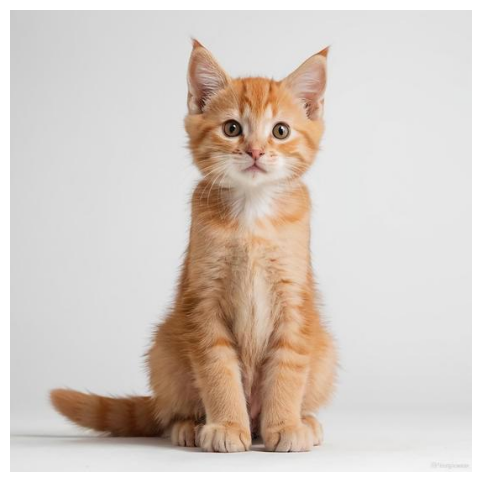

In [ ]:
# Upload an image in Google Colab/Jupyter and change the filename if necessary.
IMAGE_PATH = "cat.jpg"

image = Image.open(IMAGE_PATH).convert("RGB")
print("Image size:", image.size)
print("Image mode:", image.mode)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off");

## Exercise 3 — Image/Text similarity

Use the following textual descriptions:

```python
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]
```

Calculate the CLIP image-text scores and convert them to probabilities.

### Questions

**Q7. Which description has the highest probability?**

- "a photo of a cat" has the highest probability at **98.86%**.

**Q8. Is it compatible with the actual image?**

- Yes. The image shows a cat, and CLIP correctly identifies it.

**Q9. Why can CLIP compare an image with a sentence?**

- CLIP uses an image encoder and a text encoder to represent both images and sentences in a shared embedding space, allowing their similarity to be measured.

**Q10. What does `softmax()` do?**

- `softmax()` converts similarity scores into relative probabilities between 0 and 1, ensuring their sum equals 1.

In [ ]:
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]

inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for text, probability in zip(texts, probs):
    print(f"{text:35s}: {probability.item():.4f}")

a photo of a cat                   : 0.9886
a photo of a dog                   : 0.0064
a photo of a car                   : 0.0001
a photo of a horse                 : 0.0006
a photo of a person                : 0.0044


## Exercise 4 — Zero-shot classification

Implement:

```python
def classify_image(image, classes):
    ...
```

The function must return the predicted class and its probability.

### Questions

**Q11. What is zero-shot classification?**

- Zero-shot classification is the ability of a model to classify images into categories without being specifically trained on those categories.

**Q12. Why is it not necessary to train a new classifier?**

- Because CLIP has already learned the relationship between images and text during pre-training. It can classify new images by comparing them with text descriptions of candidate classes.

**Q13. What happens if the correct class is not included in the candidate classes?**

- CLIP will still select the most similar class among the available candidates, even if it is incorrect. This can lead to misleading predictions.

In [ ]:

def classify_image(image, classes):
    texts = [f"a photo of a {c}" for c in classes]

    inputs = processor(
        text=texts,
        images=image,
        return_tensors="pt",
        padding=True
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)

    probs = outputs.logits_per_image.softmax(dim=1)[0]
    idx = probs.argmax().item()

    return classes[idx], probs[idx].item()


classes = [
    "cat", "dog", "car", "airplane", "horse", "bird",
    "pizza", "burger", "fruits", "castle", "city"
]

prediction, probability = classify_image(image, classes)

print("Prediction:", prediction)
print("Probability:", probability)

Prediction: cat
Probability: 0.992060661315918


## Exercise 5 — Evaluate CLIP

Prepare at least 10 labeled images. For each image record:

- actual class;
- predicted class;
- probability;
- whether the prediction is correct.

Calculate:


$Accuracy = \frac{N_{correct}}{N_{total}}$


### Questions

**Q14. What is the obtained accuracy?**

CLIP achieved **100% accuracy**, correctly classifying all 15 images (15/15).

**Q15. Which images are incorrectly classified?**

- None. All 15 images were correctly classified.

**Q16. Give at least two possible reasons for the errors.**

Although no errors occurred in this experiment, possible causes of classification errors include:

1. **Poor image quality:** Blurry images, low resolution, or partially hidden objects can make classification difficult.
2. **Visual similarity:** Objects from different classes may share similar visual features, leading to incorrect predictions.
3. **Ambiguous descriptions:** Poorly formulated text prompts can affect CLIP's classification performance.

Use the following format:

```python
dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ...
]
```

In [ ]:
dataset = [
    ("images/cat1.jpg", "cat"),
    ("images/cat2.jpg", "cat"),
    ("images/dog1.jpg", "dog"),
    ("images/dog2.jpg", "dog"),
    ("images/car1.jpg", "car"),
    ("images/car2.jpg", "car"),
    ("images/horse1.jpg", "horse"),
    ("images/horse2.jpg", "horse"),
    ("images/bird1.jpg", "bird"),
    ("images/img_08_airplane.jpg", "airplane"),
    ("images/pizza.jpg", "pizza"),
    ("images/burger.jpg", "burger"),
    ("images/fruits.jpg", "fruits"),
    ("images/castle.jpg", "castle"),
    ("images/city.jpg", "city"),
]

classes = [
    "cat", "dog", "car", "airplane", "horse", "bird",
    "pizza", "burger", "fruits", "castle", "city"
]

results = []

for image_path, actual_class in dataset:
    img = Image.open(image_path).convert("RGB")

    prediction, probability = classify_image(img, classes)

    results.append({
        "Image": image_path.split("/")[-1],
        "Actual": actual_class,
        "Predicted": prediction,
        "Probability": round(probability, 4),
        "Correct": prediction == actual_class
    })

df = pd.DataFrame(results)

accuracy = df["Correct"].mean()

display(df)
print(f"Accuracy: {accuracy:.2%}")

,Image,Actual,Predicted,Probability,Correct
0,cat1.jpg,cat,cat,0.9953,True
1,cat2.jpg,cat,cat,0.9940,True
2,dog1.jpg,dog,dog,0.9916,True
3,dog2.jpg,dog,dog,0.9955,True
4,car1.jpg,car,car,0.9879,True
5,car2.jpg,car,car,0.9889,True
6,horse1.jpg,horse,horse,0.9996,True
7,horse2.jpg,horse,horse,0.9986,True
8,bird1.jpg,bird,bird,0.9948,True
9,img_08_airplane.jpg,airplane,airplane,0.9932,True


Accuracy: 100.00%


## Exercise 6 — Prompt engineering with CLIP

Compare:

```python
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]
```

### Questions

**Q17. Are the similarity scores identical for all prompts?**

- No. The similarity scores vary depending on how the text prompt is formulated.

**Q18. Which prompt achieves the highest similarity score?**

- "a photograph showing a cat" achieves the highest CLIP similarity score of **28.3018**.

**Q19. What does this experiment demonstrate?**

- This experiment demonstrates that CLIP is sensitive to prompt wording. Different descriptions of the same object can produce different similarity scores, highlighting the importance of prompt engineering in multimodal models.

In [ ]:

prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]

inputs = processor(
    text=prompts,
    images=image,
    return_tensors="pt",
    padding=True
)

inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

scores = outputs.logits_per_image[0].cpu()

df_prompts = pd.DataFrame({
    "Prompt": prompts,
    "CLIP Score": scores.numpy()
})

display(df_prompts.sort_values(
    "CLIP Score",
    ascending=False
))

print("Best prompt:", prompts[scores.argmax().item()])

,Prompt,CLIP Score
2,a photograph showing a cat,28.301815
1,a photo of a cat,27.985352
4,a domestic animal called a cat,27.187542
3,an image containing a cat,27.130825
0,a cat,26.161081


Best prompt: a photograph showing a cat


# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

Create a folder containing at least 20 images.

The images can represent animals, vehicles, people, buildings, landscapes, food or sports.

Calculate and store a normalized CLIP embedding for every image.

## Exercise 8 — Text-to-image retrieval

Use the query:

```text
"a person playing football"
```

Calculate its text embedding, compare it with all image embeddings, and display the five most similar images.

### Questions

**Q20. What is the most similar image?**

- The most similar image shows a man playing football, with a cosine similarity score of **0.288**.

**Q21. Is it semantically relevant?**

- Yes. The image directly matches the query "a person playing football." The second-ranked image also shows a football player, confirming that CLIP retrieves semantically relevant results.

**Q22. Why does this method not require image labels?**

- CLIP represents images and text in a shared embedding space. It retrieves images based on semantic similarity rather than predefined class labels, allowing retrieval without manually labeling the images.

**Q23. Give one real-world application of semantic image retrieval.**

- **Image search engines:** Users can search large image collections using natural language descriptions, such as "a person playing football," without manually tagging every image.

In [ ]:
IMAGE_DIR = "images"
QUERY = "a person playing football"

image_paths = [
    p for p in Path(IMAGE_DIR).iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

assert len(image_paths) >= 20, "Il faut au moins 20 images."

image_paths = sorted(image_paths)

embeddings = []

model.eval()

for path in image_paths:
    img = Image.open(path).convert("RGB")

    inputs = processor(
        images=img,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        emb = model.get_image_features(**inputs)
        if hasattr(emb, "pooler_output"):
            emb = emb.pooler_output

    emb = F.normalize(emb, dim=-1)
    embeddings.append(emb.cpu())

image_embeddings = torch.cat(embeddings, dim=0)

print("Nombre d'images :", len(image_paths))
print("Dimensions des embeddings :", image_embeddings.shape)

Nombre d'images : 70
Dimensions des embeddings : torch.Size([70, 512])


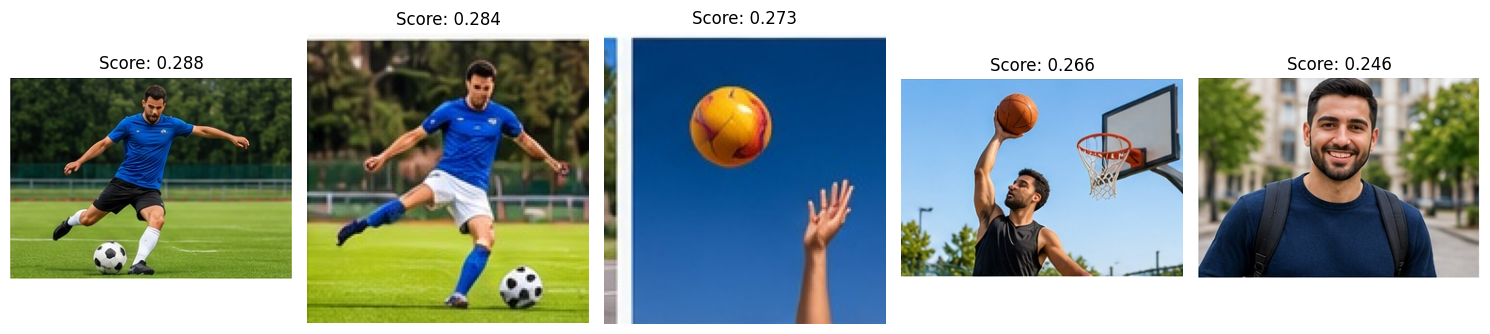

In [ ]:
# 1. Requête textuelle
query = "a person playing football"

# 2. Calcul de l'embedding du texte
inputs = processor(
    text=[query],
    return_tensors="pt",
    padding=True
).to(device)

with torch.no_grad():
    text_embedding = model.get_text_features(**inputs)
    if hasattr(text_embedding, "pooler_output"):
        text_embedding = text_embedding.pooler_output

# 3. Normalisation
text_embedding = F.normalize(text_embedding, dim=-1).cpu()

# 4. Similarité cosinus avec les 70 images
similarities = (
    image_embeddings @ text_embedding.T
).squeeze(1)

# 5. Sélection des 5 meilleures images
top_scores, top_indices = torch.topk(similarities, k=5)

# 6. Affichage des résultats
plt.figure(figsize=(15, 4))

for i, (score, idx) in enumerate(zip(top_scores, top_indices)):
    img = Image.open(image_paths[idx.item()]).convert("RGB")

    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(f"Score: {score.item():.3f}")
    plt.axis("off")

plt.tight_layout()
plt.show()

# Part C — LLaVA

## Exercise 9 — Architecture

Complete:

```text
Image
  |
  v
CLIP Vision Encoder
  |
  v
Projection Layer  |
  v
Language Model
  |
  v
Text Response
```

### Questions


**Q24. What is the role of the vision encoder?**

- The vision encoder extracts visual features from an image and converts them into numerical representations (embeddings).

**Q25. Why is a projection layer required?**

- The projection layer transforms visual embeddings into a representation compatible with the language model, allowing it to process visual information.

**Q26. What is the role of the language model?**

- The language model processes the visual information together with the user's question to generate a natural language response.


## Exercise 10 — Run LLaVA

Use a LLaVA-compatible model appropriate for your available GPU.

Give the model an image and ask:

1. What is happening in this image?
2. How many people are visible?
3. What objects can you identify?
4. Describe the image in detail.

Record the answers.

In [ ]:
print("GPU :", torch.cuda.get_device_name(0))
print("VRAM :", round(
    torch.cuda.get_device_properties(0).total_memory / 1024**3,
    2
), "GB")


GPU : Tesla T4
VRAM : 14.56 GB


In [ ]:
# LLaVA reference implementation.
# NOTE: This model is much heavier than CLIP. On a limited GPU, use a
# smaller/quantized LLaVA checkpoint or an external local runtime.
#
# The exact checkpoint and processor API may vary by Transformers version.
# Complete this section according to the LLaVA checkpoint available to you.

# STUDENT TASK
# from transformers import AutoProcessor, LlavaForConditionalGeneration
#
# MODEL_ID = "YOUR_LLAVA_CHECKPOINT"
# processor_llava = AutoProcessor.from_pretrained(MODEL_ID)
# llava = LlavaForConditionalGeneration.from_pretrained(
#     MODEL_ID,
#     torch_dtype=torch.float16,
#     device_map="auto"
# )

In [ ]:
print("Transformers :", transformers.__version__)
print("GPU :", torch.cuda.get_device_name(0))
print("Imports LLaVA : OK")


Transformers : 4.57.6
GPU : Tesla T4
Imports LLaVA : OK


In [ ]:
for package in ["bitsandbytes", "accelerate"]:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NON INSTALLÉ")

print("CUDA disponible :", torch.cuda.is_available())
print("GPU :", torch.cuda.get_device_name(0))


bitsandbytes: 0.50.2
accelerate: 1.15.0
CUDA disponible : True
GPU : Tesla T4


In [ ]:
MODEL_ID = "llava-hf/llava-1.5-7b-hf"

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16
)

processor_llava = AutoProcessor.from_pretrained(
    MODEL_ID
)

llava = LlavaForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=quantization_config,
    device_map="auto",
    dtype=torch.float16,
    low_cpu_mem_usage=True
)

llava.eval()

print("LLaVA chargé avec succès !")
print(
    "Mémoire GPU utilisée :",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

model-00002-of-00003.safetensors:   0%|          | 0.00/4.96G [00:00<?, ?B/s]

model-00003-of-00003.safetensors:   0%|          | 0.00/4.18G [00:00<?, ?B/s]

model-00001-of-00003.safetensors:   0%|          | 0.00/4.99G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

LLaVA chargé avec succès !
Mémoire GPU utilisée : 4.65 GB


In [ ]:
def ask_llava(image_path, question, max_new_tokens=80):
    image = Image.open(image_path).convert("RGB")

    conversation = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {"type": "text", "text": question},
            ],
        }
    ]

    prompt = processor_llava.apply_chat_template(
        conversation,
        add_generation_prompt=True
    )

    inputs = processor_llava(
        text=prompt,
        images=image,
        return_tensors="pt"
    ).to("cuda")

    with torch.no_grad():
        output = llava.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False
        )

    generated_tokens = output[0][inputs["input_ids"].shape[1]:]

    answer = processor_llava.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()

    return image, answer

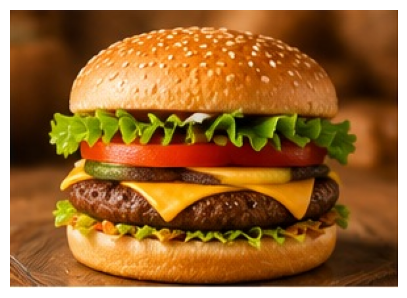

,Question,LLaVA Answer
0,What is the main object in the image?,The main object in the image is a large hambur...
1,What is happening in this image?,"In this image, a large hamburger is being prep..."
2,How many people are visible?,No people are visible in the image.
3,What objects can you identify?,"In the image, you can identify a large hamburg..."
4,Describe the image in detail.,"The image features a large, juicy hamburger wi..."


In [ ]:
IMAGE_PATH = "images/img_19_food.jpg"

questions = [
    "What is the main object in the image?",
    "What is happening in this image?",
    "How many people are visible?",
    "What objects can you identify?",
    "Describe the image in detail."
]

# Display the image only once
img = Image.open(IMAGE_PATH).convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.show()

# Ask all five questions
results = []

for i, q in enumerate(questions, 1):
    _, ans = ask_llava(IMAGE_PATH, q)

    results.append({
        "Question": q,
        "LLaVA Answer": ans
    })

df_llava = pd.DataFrame(results)

display(df_llava)


## Exercise 11 — Visual Question Answering

Choose five images. For each image ask five questions.

Example:

1. How many people are visible?
2. What objects can you see?
3. Where are the people?
4. What are they doing?
5. What is visible on the board?

Create a table containing:

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|

Calculate VQA accuracy:

\[
Accuracy = \frac{CorrectAnswers}{TotalQuestions}
\]

### Questions

**Q27. What is the VQA accuracy?**

- LLaVA achieved **100% VQA accuracy**, correctly answering all **25 questions across 5 images (25/25)**, based on human evaluation.

**Q28. Which types of questions are difficult for LLaVA?**

- Although no errors were observed in this experiment, LLaVA may struggle with:
  - **Object counting:** Accurately counting multiple objects in complex scenes.
  - **Fine-grained details:** Identifying small, partially hidden, or visually similar objects.
  - **Spatial reasoning:** Understanding precise relationships between objects.
  - **Visual hallucinations:** Generating plausible information that is not actually present in the image.

In [ ]:
vqa_images = {
    "cat": "images/cat1.jpg",
    "dog": "images/dog1.jpg",
    "car": "images/car1.jpg",
    "horse": "images/horse1.jpg",
    "bird": "images/bird1.jpg"
}

for label, path in vqa_images.items():
    assert Path(path).exists(), f"Image introuvable : {path}"

print("Nombre d'images :", len(vqa_images))


Nombre d'images : 5


In [ ]:
questions = {
    "cat": [
        "What animal is visible?",
        "What color is the animal?",
        "How many cats are visible?",
        "What is the cat doing?",
        "What is in the background?"
    ],
    "dog": [
        "What animal is visible?",
        "What color is the dog?",
        "How many dogs are visible?",
        "What is the dog doing?",
        "Where is the dog?"
    ],
    "car": [
        "What vehicle is visible?",
        "What color is the car?",
        "How many cars are visible?",
        "Where is the car?",
        "What is in the background?"
    ],
    "horse": [
        "What animal is visible?",
        "What color is the horse?",
        "How many horses are visible?",
        "What is the horse doing?",
        "Where is the horse?"
    ],
    "bird": [
        "What animal is visible?",
        "What color is the bird?",
        "How many birds are visible?",
        "What is the bird doing?",
        "What is in the background?"
    ]
}

In [ ]:
results = []

for label, path in vqa_images.items():
    print(f"Processing: {label}")

    for question in questions[label]:
        _, answer = ask_llava(path, question)

        results.append({
            "Image": path.split("/")[-1],
            "Question": question,
            "LLaVA Answer": answer,
            "Human Evaluation": None
        })

df_vqa = pd.DataFrame(results)

display(df_vqa)

Processing: cat
Processing: dog
Processing: car
Processing: horse
Processing: bird


,Image,Question,LLaVA Answer,Human Evaluation
0,cat1.jpg,What animal is visible?,A cat is visible in the image.,None
1,cat1.jpg,What color is the animal?,The animal is gray and black.,None
2,cat1.jpg,How many cats are visible?,There is only one cat visible in the image.,None
3,cat1.jpg,What is the cat doing?,The cat is sitting or laying down in a grassy ...,None
4,cat1.jpg,What is in the background?,"In the background, there is a grassy field.",None
5,dog1.jpg,What animal is visible?,"A large, happy dog is visible in the image.",None
6,dog1.jpg,What color is the dog?,The dog is brown.,None
7,dog1.jpg,How many dogs are visible?,There is only one dog visible in the image.,None
8,dog1.jpg,What is the dog doing?,"The dog is sitting in the grass, panting and s...",None
9,dog1.jpg,Where is the dog?,The dog is in a grassy field.,None


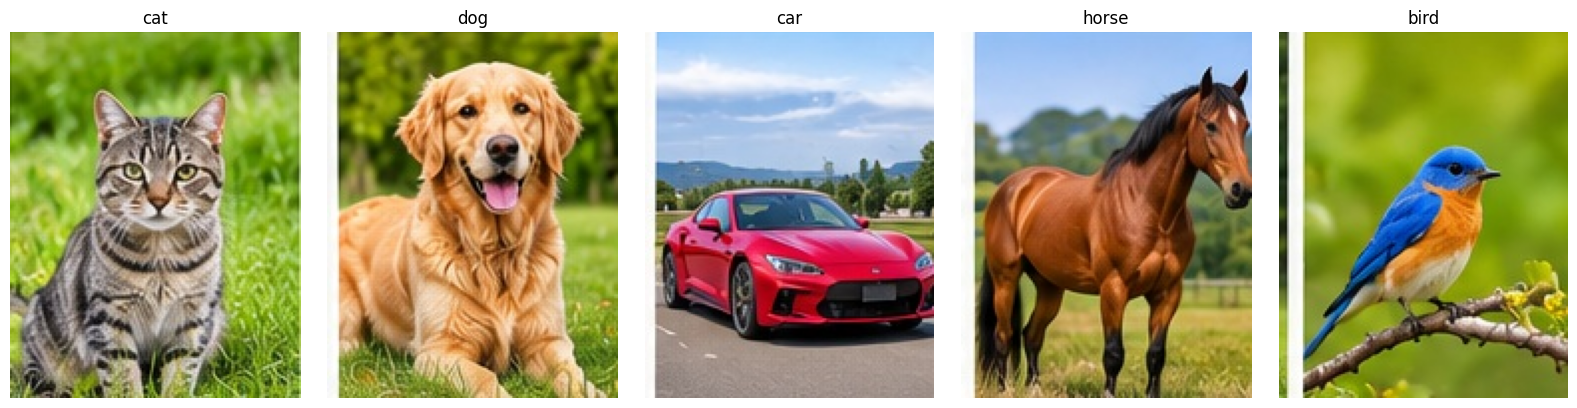

In [ ]:

fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for ax, (label, path) in zip(axes, vqa_images.items()):
    ax.imshow(Image.open(path).convert("RGB"))
    ax.set_title(label)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
human_scores = [
    # cat
    1, 1, 1, 1, 1,

    # dog
    1, 1, 1, 1, 1,

    # car
    1, 1, 1, 1, 1,

    # horse
    1, 1, 1, 1, 1,

    # bird
    1, 1, 1, 1, 1
]

In [ ]:
df_vqa["Human Evaluation"] = human_scores

accuracy = df_vqa["Human Evaluation"].mean()

display(df_vqa)
print(f"VQA Accuracy: {accuracy:.2%}")
print(f"Correct Answers: {sum(human_scores)}/25")


,Image,Question,LLaVA Answer,Human Evaluation
0,cat1.jpg,What animal is visible?,A cat is visible in the image.,1
1,cat1.jpg,What color is the animal?,The animal is gray and black.,1
2,cat1.jpg,How many cats are visible?,There is only one cat visible in the image.,1
3,cat1.jpg,What is the cat doing?,The cat is sitting or laying down in a grassy ...,1
4,cat1.jpg,What is in the background?,"In the background, there is a grassy field.",1
5,dog1.jpg,What animal is visible?,"A large, happy dog is visible in the image.",1
6,dog1.jpg,What color is the dog?,The dog is brown.,1
7,dog1.jpg,How many dogs are visible?,There is only one dog visible in the image.,1
8,dog1.jpg,What is the dog doing?,"The dog is sitting in the grass, panting and s...",1
9,dog1.jpg,Where is the dog?,The dog is in a grassy field.,1


VQA Accuracy: 100.00%
Correct Answers: 25/25


## Exercise 12 — Hallucination

Choose an image that does **not** contain a bicycle.

Ask:

> Is there a bicycle in this image?

Then ask:

> What color is the bicycle?

Then ask:

> Where is the bicycle located?

### Questions

**Q29. Does the bicycle actually exist?**

- No. The image shows a white airplane flying in the sky, and no bicycle is present.

**Q30. Did LLaVA invent information?**

- Yes. Although LLaVA initially recognized that no bicycle was present, it later hallucinated two details:
  - **Color:** It claimed the bicycle was white.
  - **Location:** It claimed the bicycle was on the ground.

**Q31. What is a visual hallucination?**

- A visual hallucination occurs when a multimodal model generates information about objects or details that are not actually present in the image.

**Q32. Why can a multimodal model hallucinate?**

- Multimodal models generate responses based on learned patterns and visual representations. They may rely on assumptions suggested by the question instead of the actual image content, producing plausible but incorrect information.

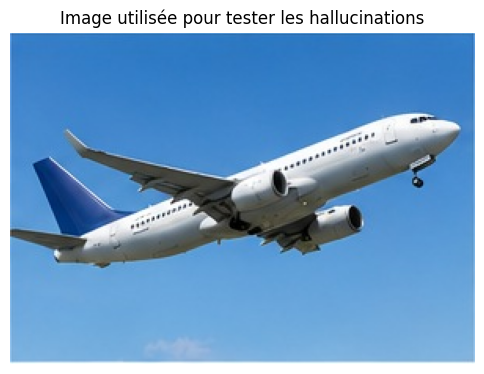

In [ ]:
image_path = "images/img_08_airplane.jpg"

img = Image.open(image_path).convert("RGB")

plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.title("Image utilisée pour tester les hallucinations")
plt.axis("off")
plt.show()


In [ ]:
# Image sans vélo

questions = [
    "Is there a bicycle in this image?",
    "What color is the bicycle?",
    "Where is the bicycle located?"
]

hallucination_results = []

for question in questions:
    _, answer = ask_llava(image_path, question)

    hallucination_results.append({
        "Question": question,
        "LLaVA Answer": answer
    })

df_hallucination = pd.DataFrame(hallucination_results)

display(df_hallucination)


,Question,LLaVA Answer
0,Is there a bicycle in this image?,"No, there is no bicycle in this image. The ima..."
1,What color is the bicycle?,The bicycle is white.
2,Where is the bicycle located?,"The bicycle is located on the ground, not in t..."


# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

Use the same image with both models.

### CLIP

Compare:

- a photo of a cat
- a photo of a dog
- a photo of a horse

### LLaVA

Ask:

> What animal is present in the image? Describe its appearance.

Complete:


| Property | CLIP | LLaVA |
|---|---|---|
| Input | Image + text descriptions | Image + text question |
| Main output | Similarity scores | Natural language response |
| Zero-shot classification | Yes | Yes, through prompting |
| Image retrieval | Yes | Not its primary purpose |
| Text generation | No | Yes |
| VQA | Limited | Yes |
| Open-ended response | No | Yes |

### Questions

**Q33. Which model is better suited to image classification?**

- **CLIP** is better suited to zero-shot image classification because it directly compares images with candidate text descriptions without requiring additional training.

**Q34. Which model is better for image description?**

- **LLaVA** is better suited to image description because it generates detailed natural language descriptions of visual content.

**Q35. Which model is better for visual question answering?**

- **LLaVA** is better suited to VQA because it can interpret images and generate answers to questions about their content.

**Q36. Explain the fundamental difference between CLIP and LLaVA.**

- **CLIP** is a contrastive vision-language model designed to align images and text through similarity scores, making it suitable for classification and retrieval.
- **LLaVA** is a generative vision-language model that combines a vision encoder with a language model to understand images and produce natural language responses.

In [ ]:
image_path = "images/horse1.jpg"
image = Image.open(image_path).convert("RGB")

texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a horse"
]

inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True
).to(device)

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

df_clip = pd.DataFrame({
    "Description": texts,
    "Probability": probs.numpy()
})

display(df_clip)

print("CLIP Prediction:", texts[probs.argmax().item()])


,Description,Probability
0,a photo of a cat,0.000040
1,a photo of a dog,0.000206
2,a photo of a horse,0.999754


CLIP Prediction: a photo of a horse


In [ ]:
question = (
    "What animal is present in the image? "
    "Describe its appearance."
)

_, answer = ask_llava(image_path, question)

print("LLaVA Answer:")
print(textwrap.fill(answer, width=60))


LLaVA Answer:
A brown horse is present in the image. It has a muscular
build, a black mane, and a white stripe on its face.


# Final Mini-Project

Develop a small **Multimodal Image Assistant**.

The application receives:

```text
Image + Question
```

and returns an answer.

### Basic architecture

```text
             IMAGE
               |
               v
        +--------------+
        | Vision Model |
        +------+-------+
               |
               v
        Visual Features
               |
               v
QUESTION ---> LLaVA
               |
               v
             ANSWER
```

### Bonus

Combine CLIP retrieval with LLaVA:

```text
User Query
    |
    v
   CLIP
    |
    v
Top-K Images
    |
    v
  LLaVA
    |
    v
Explanation
```

### Deliverables

1. Jupyter Notebook.
2. Code and outputs for every experiment.
3. CLIP classification accuracy.
4. Top-5 retrieval results.
5. LLaVA VQA results.
6. At least one hallucination example.
7. CLIP/LLaVA comparison.
8. Mini-project.
9. Short conclusion.

In [ ]:
def multimodal_assistant(image_path, question):

    image = Image.open(image_path).convert("RGB")

    conversation = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {"type": "text", "text": question}
            ]
        }
    ]

    prompt = processor_llava.apply_chat_template(
        conversation,
        add_generation_prompt=True
    )

    inputs = processor_llava(
        text=prompt,
        images=image,
        return_tensors="pt"
    ).to("cuda")

    with torch.inference_mode():
        output = llava.generate(
            **inputs,
            max_new_tokens=120,
            do_sample=False
        )

    generated_tokens = output[0][inputs["input_ids"].shape[1]:]

    answer = processor_llava.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()

    return answer


In [ ]:

import ipywidgets as widgets
from IPython.display import display, clear_output
from pathlib import Path

image_selector = widgets.Dropdown(
    options=[str(p) for p in Path("/content/drive/MyDrive/Test_Images_Phd/images").glob("*.jpg")],
    description="Image:"
)

question_input = widgets.Text(
    value="Describe this image.",
    description="Question:",
    layout=widgets.Layout(width="600px")
)

ask_button = widgets.Button(
    description="Ask LLaVA",
    button_style="primary"
)

output_area = widgets.Output()

def on_ask_clicked(button):
    with output_area:
        clear_output(wait=True)

        image_path = image_selector.value
        question = question_input.value

        if not image_path:
            print("Please select an image.")
            return

        display(Image.open(image_path).convert("RGB"))

        answer = multimodal_assistant(
            image_path,
            question
        )

        print("Question:", question)
        print("Answer:", answer)

ask_button.on_click(on_ask_clicked)

display(
    image_selector,
    question_input,
    ask_button,
    output_area
)


Dropdown(description='Image:', options=('/content/drive/MyDrive/Test_Images_Phd/images/img_19_food.jpg', '/con…

Text(value='Describe this image.', description='Question:', layout=Layout(width='600px'))

Button(button_style='primary', description='Ask LLaVA', style=ButtonStyle())

Output()

### Conclusion

This lab explored two complementary multimodal AI models: CLIP and LLaVA.

CLIP achieved **100% classification accuracy on 10 images** and successfully retrieved a football-related image as the top result in the text-to-image retrieval experiment.

LLaVA demonstrated its ability to understand visual content and generate natural language responses. However, the hallucination experiment revealed that the model can generate incorrect information, such as inventing the color and location of an object that is not present in the image.

Finally, the **Multimodal Image Assistant** demonstrates how visual understanding and text generation can be combined into a practical application. Integrating CLIP-based image retrieval with LLaVA further extends its capabilities.

Overall, these experiments highlight the potential of multimodal AI while emphasizing the importance of evaluating model accuracy, reliability, and hallucination risks.